# 1: Target Definition and Baseline Model

**Owner**: Aaliyah (Predictive Analytics & Acquisition Strategist), **Ticket** #11

Build a defined success target and a baseline model that the stronger models must beat.


In [115]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor


from capstone.dataset import load_anime
from capstone.dataset import load_reviews

# Load cleaned anime dataset
anime_df = load_anime()
reviews_df = load_reviews()
print("Anime shape:", anime_df.shape)
print("Reviews shape:", reviews_df.shape)
print("Top missing columns in anime dataset:\n", anime_df.isnull().sum().sort_values(ascending=False).head(10))

print("\nAnime columns:\n", anime_df.columns)
print("\n Reviews columns:\n", reviews_df.columns)

Anime shape: (16216, 77)
Reviews shape: (130517, 11)
Top missing columns in anime dataset:
 mean_character_score         8303
mean_story_score             8295
mean_sound_score             8295
mean_enjoyment_score         8294
mean_animation_score         8284
adjusted_positive_share      8103
adjusted_review_score        8103
mean_review_score            8103
mean_review_sentiment        8103
adjusted_review_sentiment    8103
dtype: int64

Anime columns:
 Index(['uid', 'title', 'synopsis', 'genre', 'episodes', 'members',
       'popularity', 'ranked', 'score', 'img_url', 'link', 'start_date',
       'end_date', 'start_year', 'is_airing', 'n_reviews', 'mean_review_score',
       'mean_story_score', 'mean_animation_score', 'mean_sound_score',
       'mean_character_score', 'mean_enjoyment_score', 'n_favorites',
       'popularity_index', 'adjusted_review_score', 'genre_count',
       'genre_action', 'genre_adventure', 'genre_cars', 'genre_comedy',
       'genre_dementia', 'genre_demons

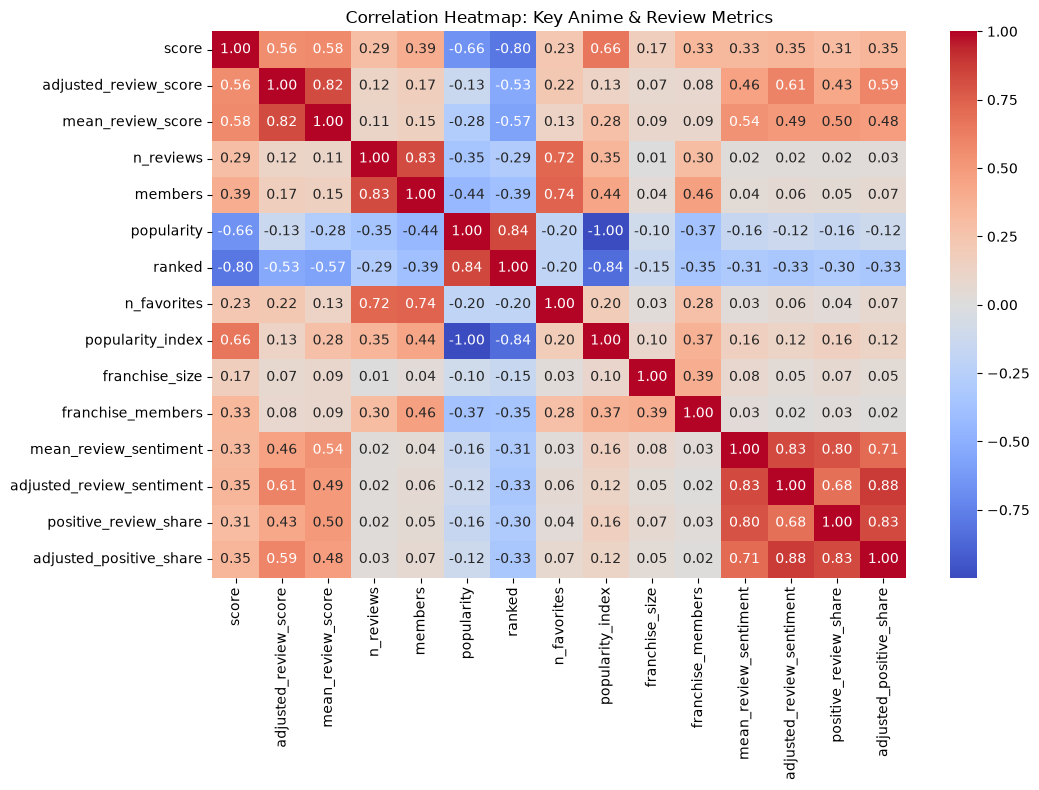

In [116]:
numeric_cols = anime_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = anime_df.select_dtypes(include=["object", "string", "category"]).columns.tolist()

# 2. Correlation heatmap on key numeric columns
key_num_cols = [
    c for c in [
        "score", "adjusted_review_score", "mean_review_score", "n_reviews",
        "members", "popularity", "ranked", "n_favorites", "popularity_index",
        "franchise_size", "franchise_members", "mean_review_sentiment",
        "adjusted_review_sentiment", "positive_review_share", "adjusted_positive_share"
    ] if c in anime_df.columns
]

corr_matrix = anime_df[key_num_cols].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap: Key Anime & Review Metrics")
plt.tight_layout()
plt.show()

In [136]:
# 3. Define targets (0-100 franchise_potential_score & top-25% high_success_flag)
work_df = anime_df.copy()
raw_potential = (
    0.45 * work_df["adjusted_review_score"].fillna(work_df["score"]).fillna(0)
    + 0.35 * np.log1p(work_df["franchise_members"].fillna(work_df["members"]).clip(lower=0))
    + 0.20 * (work_df["adjusted_positive_share"].fillna(work_df["positive_review_share"]).fillna(0.5) * 10.0)
)
min_p, max_p = raw_potential.min(), raw_potential.max()
work_df["franchise_potential_score"] = ((raw_potential - min_p) / (max_p - min_p)) * 100.0
threshold_75 = work_df["franchise_potential_score"].quantile(0.75)
work_df["high_success_flag"] = (work_df["franchise_potential_score"] >= threshold_75).astype(int)

# Exclude identifier, text, date, and target-derivation columns to prevent leakage
leakage_and_id_cols = {
    "uid", "title", "synopsis", "genre", "franchise", "img_url", "link",
    "start_date", "end_date", "score", "ranked", "mean_review_score",
    "mean_story_score", "mean_animation_score", "mean_sound_score",
    "mean_character_score", "mean_enjoyment_score", "popularity_index",
    "adjusted_review_score", "franchise_members", "positive_review_share",
    "adjusted_positive_share", "franchise_potential_score", "high_success_flag"
}

feature_cols = [c for c in work_df.columns if c not in leakage_and_id_cols]
num_features = [c for c in feature_cols if pd.api.types.is_numeric_dtype(work_df[c])]
cat_features = [c for c in feature_cols if c not in num_features]

X = work_df[feature_cols]
# explicitly drop 'franchise' from X before splitting
X = X.drop(columns=["franchise"], errors="ignore")
print("Any 'franchise' in X?", "franchise" in X.columns)

y_cls = work_df["high_success_flag"]
y_reg = work_df["franchise_potential_score"]

X_train, X_test, y_cls_train, y_cls_test, y_reg_train, y_reg_test = train_test_split(
    X, y_cls, y_reg, test_size=0.2, random_state=42, stratify=y_cls
)

Any 'franchise' in X? False


In [137]:
# StandardScaler inside leakage-free Pipeline
preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_features)
])

# Baseline Classifier (Logistic Regression) & Regressor (Decision Tree)
logreg_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])
dt_reg_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeRegressor(max_depth=6, random_state=42))
])

logreg_pipe.fit(X_train, y_cls_train)
dt_reg_pipe.fit(X_train, y_reg_train)

cls_proba = logreg_pipe.predict_proba(X_test)[:, 1]
cls_pred = (cls_proba >= 0.5).astype(int)
reg_pred = dt_reg_pipe.predict(X_test)

print(f"Baseline LogReg ROC-AUC: {roc_auc_score(y_cls_test, cls_proba):.4f} | F1: {f1_score(y_cls_test, cls_pred):.4f}")
print(f"Baseline DT Regressor RMSE: {np.sqrt(mean_squared_error(y_reg_test, reg_pred)):.4f} | MAE: {mean_absolute_error(y_reg_test, reg_pred):.4f}")

Baseline LogReg ROC-AUC: 0.9856 | F1: 0.8914
Baseline DT Regressor RMSE: 5.6005 | MAE: 3.9490


* Schema & Missingness Audit Inspect info(), isnull().sum(), and select_dtypes on anime_df and reviews_df to catch any string-formatted numeric fields or missing values before modeling.

* Correlation Heatmap & Redundancy Check (Module 6 Part 2): Run .corr() and sns.heatmap(..., annot=True, cmap="coolwarm", fmt=".2f") across numeric signals—such as score, adjusted_review_score, mean_review_score, n_reviews, members, popularity, n_favorites, franchise_size, franchise_members, mean_review_sentiment, adjusted_review_sentiment, and positive_review_share—to inspect relationships and avoid target leakage or collinearity traps.

* Leakage-Safe Baseline Models (Module 7 Part 3): Define a 0–100 franchise_potential_score and top-25% high_success_flag (excluding direct score/rank leakage columns from predictors), standardize numeric predictors inside a Pipeline with StandardScaler(), and fit baseline Logistic Regression and Decision Tree models.

# 2. Model Comparison & Feature Importance
**Ticket:** #12


In [138]:
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

# 1. Check top correlated feature pairs among predictors (collinearity awareness)
pred_corr = work_df[num_features].corr().abs()
upper_tri = pred_corr.where(np.triu(np.ones(pred_corr.shape), k=1).astype(bool))
high_corr_pairs = (
    upper_tri.stack()
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "abs_corr"})
    .sort_values("abs_corr", ascending=False)
)
print("Top correlated predictor pairs:\n", high_corr_pairs.head(10))

Top correlated predictor pairs:
                   feature_1                  feature_2  abs_corr
2969  mean_review_sentiment  adjusted_review_sentiment  0.831931
60                  members                  n_reviews  0.827752
61                  members                n_favorites  0.736005
281               n_reviews                n_favorites  0.723553
117              popularity                genre_count  0.485750
393             genre_count               genre_action  0.476129
1466            genre_mecha               genre_sci_fi  0.451957
57                  members                 popularity  0.439864
133              popularity                 genre_kids  0.430894
2857         franchise_size                  is_sequel  0.429423


In [139]:
# 2. Compare candidate classification models via Stratified K-Fold CV
classifiers = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "DecisionTree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_records = []

for name, clf in classifiers.items():
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    scores = cross_validate(pipe, X_train, y_cls_train, cv=cv, scoring=["roc_auc", "f1", "accuracy"], n_jobs=-1)
    for fold_idx in range(5):
        cv_records.append({
            "model": name,
            "roc_auc": scores["test_roc_auc"][fold_idx],
            "f1": scores["test_f1"][fold_idx],
            "accuracy": scores["test_accuracy"][fold_idx]
        })

cv_summary_df = pd.DataFrame(cv_records)

# Style grouped aggregation across models
model_comparison = cv_summary_df.groupby("model")[["roc_auc", "f1", "accuracy"]].agg(["mean", "std", "min", "max"])
print("\nCross-Validation Comparison:\n", model_comparison)


Cross-Validation Comparison:
                      roc_auc                                      f1  \
                        mean       std       min       max      mean   
model                                                                  
DecisionTree        0.976981  0.004370  0.970274  0.980856  0.870821   
GradientBoosting    0.988554  0.001869  0.986981  0.990943  0.901022   
LogisticRegression  0.984196  0.002287  0.981648  0.987107  0.881058   
RandomForest        0.988046  0.002168  0.985325  0.990364  0.900698   

                                                  accuracy            \
                         std       min       max      mean       std   
model                                                                  
DecisionTree        0.014475  0.853951  0.887684  0.936401  0.006896   
GradientBoosting    0.012157  0.889930  0.914764  0.950586  0.005569   
LogisticRegression  0.014101  0.861465  0.896013  0.941258  0.006425   
RandomForest        0.014692  0.

In [140]:
# 3. Extract feature importances from fitted Random Forest & Gradient Boosting models
rf_pipe = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))])
gb_pipe = Pipeline([("prep", preprocessor), ("model", GradientBoostingClassifier(random_state=42))])

rf_pipe.fit(X_train, y_cls_train)
gb_pipe.fit(X_train, y_cls_train)

feat_names = rf_pipe.named_steps["prep"].get_feature_names_out()
imp_df = pd.DataFrame({
    "feature": feat_names,
    "rf_importance": rf_pipe.named_steps["model"].feature_importances_,
    "gb_importance": gb_pipe.named_steps["model"].feature_importances_
}).sort_values("gb_importance", ascending=False)

print("\nTop 15 Features by Gradient Boosting Importance:\n", imp_df.head(15))


Top 15 Features by Gradient Boosting Importance:
                            feature  rf_importance  gb_importance
2                  num__popularity       0.169124       0.652083
51             num__franchise_size       0.090585       0.106936
54  num__adjusted_review_sentiment       0.088085       0.056031
53      num__mean_review_sentiment       0.086059       0.055854
6                 num__n_favorites       0.095617       0.041768
52                  num__is_sequel       0.050808       0.041440
1                     num__members       0.175504       0.018872
3                  num__start_year       0.030195       0.011591
5                   num__n_reviews       0.070948       0.009511
0                    num__episodes       0.020573       0.003778
50                 num__genre_yuri       0.000376       0.000263
7                 num__genre_count       0.025719       0.000204
42        num__genre_slice_of_life       0.003105       0.000202
24                num__genre_magic     

* `Collinearity & Redundancy Check (Module 6 Reflection): Inspect highly correlated predictors (such as members vs. n_favorites vs. franchise_size, or mean_review_sentiment vs. adjusted_review_sentiment) so correlated features don't crowd out other informative signals like is_sequel, genre_count, episodes, or n_reviews.

* Grouped Metric & Importance Summaries (Module 7 Part 6–7): Compare cross-validation results across Decision Tree, Random Forest, Logistic Regression, and Gradient Boosting using .groupby().agg(["mean", "std", "min", "max"]), and rank top features across models.

* Correlation vs. Causation Note (Module 6 Part 4 & Reflection): Flag cases where high importance reflects selection or franchise carry-over (e.g., sequels or high-member franchises already having a dedicated audience) rather than guaranteed streaming performance on its own.

# 3. Strategic Ranking System

In [142]:

# Fit regression model on full training data to predict franchise_potential_score
gb_reg_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", GradientBoostingRegressor(random_state=42))
])
gb_reg_pipe.fit(X_train, y_reg_train)

scored_df = work_df[["uid", "title", "genre", "episodes", "is_sequel", "franchise_size", "n_reviews", "adjusted_review_sentiment", "mean_review_sentiment"]].copy()
scored_df["pred_success_prob"] = gb_pipe.predict_proba(X)[:, 1]
scored_df["pred_potential_score"] = gb_reg_pipe.predict(X)
scored_df["sentiment_signal"] = scored_df["adjusted_review_sentiment"].fillna(scored_df["mean_review_sentiment"]).fillna(0.0)

# Module 7 style StandardScaler on ranking components
rank_scaler = StandardScaler()
z_signals = rank_scaler.fit_transform(
    scored_df[["pred_success_prob", "pred_potential_score", "sentiment_signal"]]
)

scored_df["z_prob"] = z_signals[:, 0]
scored_df["z_potential"] = z_signals[:, 1]
scored_df["z_sentiment"] = z_signals[:, 2]

# Composite acquisition score (adjustable weights)
scored_df["acquisition_priority_score"] = (
    0.45 * scored_df["z_prob"]
    + 0.35 * scored_df["z_potential"]
    + 0.20 * scored_df["z_sentiment"]
)

top_10_df = (
    scored_df.sort_values("acquisition_priority_score", ascending=False)
    .head(10)
    .reset_index(drop=True)
)
top_10_df["rank"] = top_10_df.index + 1

scored_df["slate_tier"] = np.where(
    scored_df["uid"].isin(top_10_df["uid"]),
    "Top 10 Slate",
    "Catalog Pool"
)

# Module 7 style .groupby().agg() summary comparing Top 10 vs. Catalog Pool
slate_comparison = scored_df.groupby("slate_tier")[
    ["acquisition_priority_score", "pred_success_prob", "pred_potential_score", "sentiment_signal"]
].agg(["mean", "min", "max"])

print("Top 10 Recommended Acquisitions:")
print(top_10_df[["rank", "title", "acquisition_priority_score", "pred_success_prob", "pred_potential_score", "sentiment_signal"]])

print("\nTop 10 Slate vs. Catalog Pool Summary:")
print(slate_comparison)

Top 10 Recommended Acquisitions:
   rank                     title  acquisition_priority_score  \
0     1                Yuru Camp△                    2.195961   
1     2    Kamisama Hajimemashita                    2.171275   
2     3                 Haikyuu!!                    2.155600   
3     4    Ouran Koukou Host Club                    2.151585   
4     5                 Barakamon                    2.143874   
5     6  Gekkan Shoujo Nozaki-kun                    2.139247   
6     7        Natsume Yuujinchou                    2.135687   
7     8            Non Non Biyori                    2.135052   
8     9                  Nichijou                    2.128889   
9    10            Lovely★Complex                    2.127302   

   pred_success_prob  pred_potential_score  sentiment_signal  
0           0.986719             89.961350          0.375977  
1           0.989306             90.617017          0.354279  
2           0.994652             95.686223          0.286004  